In [13]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pypulseq as pp
import MRzeroCore as mr0
import torchkbnufft as tkbn
from pypulseq import Sequence
import torch.nn.functional as F

/tmp/ipykernel_186/3059634312.py:32: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf, gz, _ = pp.make_sinc_pulse(


Timing check passed successfully


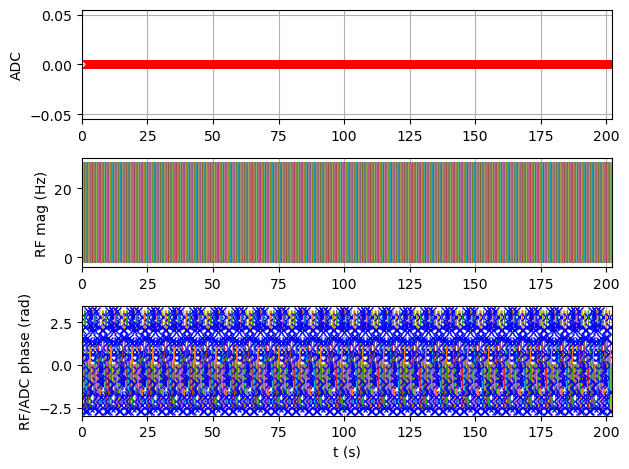

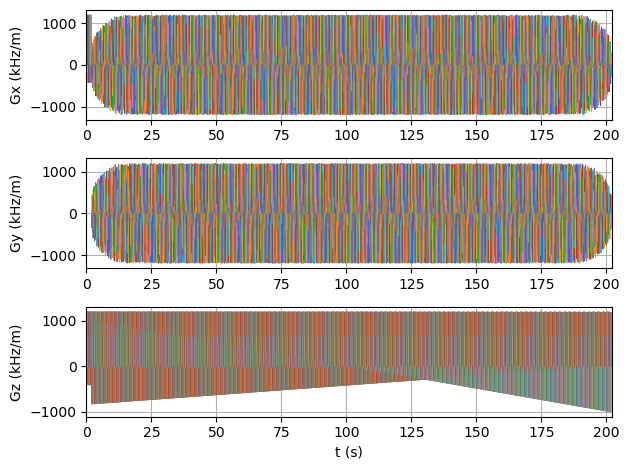

In [14]:
def main(plot: bool, write_seq: bool, seq_filename: str = "gre_radial_pypulseq.seq"):
    # ======
    # SETUP
    # ======
    seq: Sequence = pp.Sequence()  # Create a new sequence object
    fov = 250e-3
    Nx = 320  # Define FOV and resolution
    alpha = 5  # Flip angle
    slice_thickness = 3e-3  # Slice thickness
    TE = 3.98e-3  # Echo time
    TR = 100e-3  # Repetition time
    Nr = 2000 # Number of radial spokes
    N_dummy = 20  # Number of dummy scans

    rf_spoiling_inc = 117  # RF spoiling increment

    # Set system limits
    system = pp.Opts(
        max_grad=28,
        grad_unit="mT/m",
        max_slew=120,
        slew_unit="T/m/s",
        rf_ringdown_time=20e-6,
        rf_dead_time=100e-6,
        adc_dead_time=10e-6,
    )

    # ======
    # CREATE EVENTS
    # ======
    # Create alpha-degree slice selection pulse and gradient
    rf, gz, _ = pp.make_sinc_pulse(
        apodization=0.5,
        duration=2e-3,
        flip_angle=alpha * np.pi / 180,
        slice_thickness=slice_thickness,
        system=system,
        time_bw_product=4,
        return_gz=True,
    )

    # Define other gradients and ADC events
    deltak = 1 / fov
    gx_base = pp.make_trapezoid(
        channel="x", flat_area=Nx * deltak, flat_time=6.4e-3 / 5, system=system
    )
    adc = pp.make_adc(
        num_samples=Nx, duration=gx_base.flat_time, delay=gx_base.rise_time, system=system
    )
    gx_pre_base = pp.make_trapezoid(
        channel="x", area=-gx_base.area / 2, duration=2e-3, system=system
    )
    gz_reph = pp.make_trapezoid(
        channel="z", area=-gz.area / 2, duration=2e-3, system=system
    )
    # Gradient spoiling
    gx_spoil_base = pp.make_trapezoid(channel="x", area=0.5 * Nx * deltak, system=system)
    gz_spoil = pp.make_trapezoid(channel="z", area=4 / slice_thickness, system=system)

    # Calculate timing
    delay_TE = (
        np.ceil(
            (
                TE
                - pp.calc_duration(gx_pre_base)
                - gz.fall_time
                - gz.flat_time / 2
                - pp.calc_duration(gx_base) / 2
            )
            / seq.grad_raster_time
        )
        * seq.grad_raster_time
    )
    delay_TR = (
        np.ceil(
            (
                TR
                - pp.calc_duration(gx_pre_base)
                - pp.calc_duration(gz)
                - pp.calc_duration(gx_base)
                - delay_TE
            )
            / seq.grad_raster_time
        )
        * seq.grad_raster_time
    )
    assert np.all(delay_TR) > pp.calc_duration(gx_spoil_base, gz_spoil)
    rf_phase = 0
    rf_inc = 0

    # ======
    # CONSTRUCT SEQUENCE
    # ======
    for i in range(Nr + N_dummy):

        # RF spoiling (unchanged)
        rf.phase_offset = rf_phase / 180 * np.pi
        adc.phase_offset = rf_phase / 180 * np.pi

        rf_inc = (rf_inc + rf_spoiling_inc) % 360
        rf_phase = (rf_phase + rf_inc) % 360

        spoke_idx = i - N_dummy
        if spoke_idx >= 0:
            phi = np.arccos(1 - 2 * (spoke_idx + 0.5) / Nr)
            theta = np.pi * (1 + np.sqrt(5)) * spoke_idx

            kx = np.sin(phi) * np.cos(theta)
            ky = np.sin(phi) * np.sin(theta)
            kz = np.cos(phi)
        else:
            # dummy scan → arbitrary direction (doesn't matter)
            kx, ky, kz = 1, 0, 0

        # ===== RF + SLICE =====
        seq.add_block(rf, gz)

        # ===== PREPHASING (NOW 3D) =====
        gx_pre = pp.make_trapezoid(
            channel="x", area=gx_pre_base.area * kx, duration=2e-3, system=system
        )

        gy_pre = pp.make_trapezoid(
            channel="y", area=gx_pre_base.area * ky, duration=2e-3, system=system
        )

        gz_pre_total = pp.make_trapezoid(
            channel="z",
            area=gx_pre_base.area * kz + gz_reph.area,
            duration=2e-3,
            system=system,
        )

        seq.add_block(gx_pre, gy_pre, gz_pre_total)

        seq.add_block(pp.make_delay(delay_TE))

        # ===== READOUT (NOW 3D) =====
        gx = pp.make_trapezoid(
            channel="x",
            amplitude=gx_base.amplitude * kx,
            flat_time=gx_base.flat_time,
            rise_time=gx_base.rise_time,
            fall_time=gx_base.fall_time,
            system=system,
        )
        gy = pp.make_trapezoid(
            channel="y",
            amplitude=gx_base.amplitude * ky,
            flat_time=gx_base.flat_time,
            rise_time=gx_base.rise_time,
            fall_time=gx_base.fall_time,
            system=system,
        )
        gz_ro = pp.make_trapezoid(
            channel="z",
            amplitude=gx_base.amplitude * kz,
            flat_time=gx_base.flat_time,
            rise_time=gx_base.rise_time,
            fall_time=gx_base.fall_time,
            system=system,
        )

        if spoke_idx >= 0:
            seq.add_block(gx, gy, gz_ro, adc)
        else:
            seq.add_block(gx, gy, gz_ro)

        # ===== SPOILING (NOW 3D) =====
        gx_spoil = pp.make_trapezoid(
            channel="x", area=gx_spoil_base.area * kx, system=system
        )
        gy_spoil = pp.make_trapezoid(
            channel="y", area=gx_spoil_base.area * ky, system=system
        )
        gz_spoil_total = pp.make_trapezoid(
            channel="z",
            area=gx_spoil_base.area * kz + gz_spoil.area,
            system=system,
        )

        seq.add_block(
            gx_spoil,
            gy_spoil,
            gz_spoil_total,
            pp.make_delay(delay_TR),
        )

    ok, error_report = seq.check_timing()
    if ok:
        print("Timing check passed successfully")
    else:
        print("Timing check failed! Error listing follows:")
        print(error_report)

    # ======
    # VISUALIZATION
    # ======
    if plot:
        seq.plot()

    # =========
    # WRITE .SEQ
    # =========
    if write_seq:
        seq.set_definition("FOV", [fov, fov, slice_thickness])
        seq.set_definition("Name", "gre_rad")
        seq.write("3D Kooshball GRE")


if __name__ == "__main__":
    main(plot=True, write_seq=True)

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.018173477 s
Compute Graph
Computing Graph: 20.72077 s
Analyze Graph
Analyzing Graph: 0.21710157 s
Converting Rust -> Python: 4.3330407 s
<<<< Rust <<<<


/tmp/ipykernel_186/2725698884.py:64: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ktraj = torch.tensor(mr_seq.get_kspace(), dtype=torch.float32)


raw ktraj shape: torch.Size([640000, 4])
fixed ktraj shape: torch.Size([3, 640000])


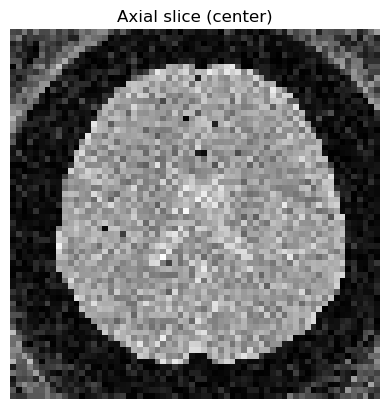

In [21]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
Nx = 320
Nr = 2000
deltak = 1/0.256
Nx_img = 64
Ny_img = 64
Nz_img = 64

raw_data = np.fromfile("subject04_crisp_v.rawb", dtype=np.uint8).reshape(362, 434, 362)
brain_mask = (raw_data >= 1) & (raw_data <= 3)
cleaned_brain = raw_data * brain_mask

pd_signal = np.zeros_like(raw_data, dtype=np.float32)
pd_signal[raw_data == 1] = 1.0
pd_signal[raw_data == 2] = 0.8
pd_signal[raw_data == 3] = 0.7

phantom_tensor = torch.from_numpy(pd_signal).to(device)

input_5d = phantom_tensor.view(1, 1, 362, 434, 362)

phantom_small = F.interpolate(
    input_5d,
    size=(Nz_img, Ny_img, Nx_img),
    mode='trilinear'
).squeeze()

pd_map = phantom_small
pd_map = pd_map.permute(1,2,0)

t1_map = torch.zeros_like(pd_map)
t1_map = torch.where(pd_map > 0.9, 4.0, t1_map)
t1_map = torch.where((pd_map <= 0.9) & (pd_map > 0.75), 1.3, t1_map)
t1_map = torch.where((pd_map <= 0.75) & (pd_map > 0.1), 0.9, t1_map)
t2_map = torch.zeros_like(pd_map)
t2_map = torch.where(pd_map > 0.9, 0.5, t2_map)
t2_map = torch.where((pd_map <= 0.9) & (pd_map > 0.75), 0.08, t2_map)
t2_map = torch.where((pd_map <= 0.75) & (pd_map > 0.1), 0.07, t2_map)
#t1_map = torch.where(pd_map > 0.5, 0.8, 1.2)
#t2_map = torch.where(pd_map > 0.5, 0.05, 0.09)
t2dash_map = torch.full_like(pd_map, 0.04)
d_map = torch.zeros_like(pd_map)
b0_map = torch.zeros_like(pd_map)
b1_map = torch.ones_like(pd_map).unsqueeze(0)
coil_sens = torch.ones_like(pd_map).unsqueeze(0)
fov_size = torch.tensor([0.256, 0.256, 0.256], device=device)

obj = mr0.VoxelGridPhantom(
    pd_map,
    t1_map,
    t2_map,
    t2dash_map,
    d_map,
    b0_map,
    b1_map,
    coil_sens,
    fov_size
)

mr_seq = mr0.Sequence.import_file("3D Kooshball GRE.seq")
signal,_ = mr0.util.simulate("3D Kooshball GRE.seq", obj)
signal = signal.flatten().to(torch.complex64)    

ktraj = torch.tensor(mr_seq.get_kspace(), dtype=torch.float32)
print("raw ktraj shape:", ktraj.shape)

ktraj = ktraj.reshape(-1, ktraj.shape[-1])[:, :3].T.contiguous()
print("fixed ktraj shape:", ktraj.shape)  

ktraj = ktraj / (deltak * Nx_img / 2) * np.pi
ktraj = ktraj.clamp(-np.pi, np.pi)
ktraj = ktraj.unsqueeze(0)              

r = torch.linalg.norm(ktraj[0], dim=0)  
dcomp = (r ** 2).view(1, 1, -1)            

signal = signal.view(1, 1, -1)             

nufft_ob = tkbn.KbNufftAdjoint(
    im_size=(Nx_img, Ny_img, Nz_img),
    grid_size=(2*Nx_img, 2*Ny_img, 2*Nz_img),
)

image = nufft_ob(signal * dcomp, ktraj)[0, 0]   

image_abs = torch.abs(image).cpu().numpy()
mid = Nz_img // 2

plt.imshow(image_abs[:, :, mid], cmap='gray')
plt.title("Axial slice (center)")
plt.axis('off')
plt.show()